# Modelo 11 — Rede neural por padrão de exames

Rede neural com uma camada oculta de neurônios sigmoide, com um submodelo para cada padrão de exames disponíveis. É o componente rede do voto do Modelo 8, separado para ser submetido sozinho.

**Aulas usadas:** 2 (qualidade e valores ausentes), 6 (redes neurais), 7 (validação e métricas), 10 (padronização por média e desvio padrão)

**Regras da competição respeitadas:**
- O conjunto de teste **não** é usado em nenhuma escolha. Toda avaliação usa validação cruzada só no treino.
- A métrica principal é o **F1-macro**, a mesma do placar do Kaggle. Também mostramos acurácia, precisão e recall de cada classe, como pede o enunciado.

## 1. Bibliotecas e funções do projeto

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from limpeza import carregar          # limpeza e correção de unidades (Aula 2)
from padroes import *                 # PorPadrao, validação e métricas (Aulas 2 e 7)
pd.set_option('display.width', 120)

## 2. Leitura e limpeza dos dados (Aula 2 — qualidade dos dados)

A função `carregar` (arquivo `limpeza.py`) aplica regras linha a linha. Nenhuma estatística é calculada aqui; médias e medianas só são calculadas dentro do treino de cada parte da validação.

| Problema encontrado | Correção |
|---|---|
| 20 registros duplicados do mesmo paciente | removidos |
| Glicose: 44 valores entre 3,1 e 21,3 (mmol/L), o resto entre 47 e 500 (mg/dL) | valores < 35 multiplicados por 18,016 |
| HbA1c: 43 valores entre 27 e 116 (mmol/mol, padrão IFCC), o resto entre 4,7 e 13,1 (%) | valores > 20 convertidos por 0,09148 × v + 2,152 |
| Peso: 23 valores acima de 140 (libras) | divididos por 2,2046 |
| Triglicerídeos com valores extremos (até 5.310) | limitados a 1000 |
| Altura em metros em alguns registros | convertida para cm; IMC calculado |
| Pressão no formato texto `120/80` ou `?` | separada em sistólica e diastólica |
| Grafias diferentes (`F`, `female`, `FEMALE`, `Não`, `0`…) | unificadas |
| Idade 0, −1 ou 999 | recalculada por ano do exame − ano de nascimento |

In [2]:
tr, te = carregar('../dados/kaggle-training/train.csv', '../dados/kaggle-test/test.csv')
y = tr['class'].values
print('treino:', tr.shape, '| teste:', te.shape)
print('classes no treino:', dict(zip(*np.unique(y, return_counts=True))))
tr.head()

### Efeito da correção de unidades

Depois da conversão, os dois exames ficam na mesma escala e separam bem as classes. Nenhum controle tem HbA1c ≥ 6,5% (limite clínico de diabetes).

In [3]:
tr.groupby('class')[['GLICOSE', 'HBA1C']].describe().T.round(1)

class              0      1
GLICOSE count  220.0  241.0
        mean    96.9  152.9
        std     13.9   67.8
        min     68.0   47.0
        25%     86.5  104.5
        50%     95.7  135.1
        75%    105.0  183.8
        max    140.0  500.0
HBA1C   count  192.0  206.0
        mean     5.5    8.1
        std      0.5    1.9
        min      4.6    4.9
        25%      5.1    6.5
        50%      5.4    7.6
        75%      5.8    9.1
        max      6.4   13.1

## 3. Padrões de exames ausentes (Aula 2 — valores ausentes)

Quase 30% dos pacientes não têm glicose, HbA1c ou ambos. Preencher com a mediana faz o paciente parecer saudável, e era exatamente aí que os primeiros modelos erravam.

A solução é **ignorar o atributo ausente** (uma das opções da aula 2): cada paciente vai para um submodelo treinado só com os atributos que ele tem.

| Padrão | Atributos do submodelo |
|---|---|
| glicose e HbA1c | glicose, HbA1c |
| só glicose | glicose + clínicos |
| só HbA1c | HbA1c + clínicos |
| nenhum exame | só clínicos |

Clínicos: triglicerídeos, pressão sistólica, IMC, idade, histórico familiar e atividade física.

In [4]:
cont = pd.DataFrame({
    'treino': pd.Series([NOME_PADRAO[p] for p in padrao_de(tr)]).value_counts(),
    'teste': pd.Series([NOME_PADRAO[p] for p in padrao_de(te)]).value_counts()})
cont['% treino'] = (100 * cont['treino'] / len(tr)).round(1)
cont['% teste'] = (100 * cont['teste'] / len(te)).round(1)
cont

,treino,teste,% treino,% teste
glicose e HbA1c,357,222,68.7,71.2
só glicose,104,53,20.0,17.0
só HbA1c,41,26,7.9,8.3
nenhum exame,18,11,3.5,3.5


## 4. O modelo (Aula 6 — redes neurais)

Arquitetura:
- **Entrada:** os atributos do submodelo, padronizados por `(valor − média) / desvio padrão` com parâmetros do treino. Diferente do KNN e da árvore, **a rede usa os atributos clínicos também para quem tem os dois exames**; na validação isso foi melhor para a rede.
- **Camada oculta:** H neurônios. Cada um faz a soma ponderada das entradas mais o viés e aplica a **sigmoide** (Aula 6, p. 6 e 7).
- **Saída:** um neurônio sigmoide. Saída ≥ 0,5 → diabetes (Aula 6, p. 11).
- **Treino:** retropropagação do erro (Aula 6, p. 21 a 23), por até 3000 épocas.

**Diferença em relação ao slide 17:** o slide atualiza os pesos com gradiente descendente após cada exemplo. Aqui usamos o otimizador **Adam** (uma variação do gradiente descendente que ajusta o passo automaticamente) e uma pequena penalização dos pesos (`alpha = 0,001`). Na comparação feita no Modelo 8, a versão exatamente como no slide teve F1 0,874 sozinha, contra 0,897 com Adam.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

def criar_rede(h):
    return PorPadrao(make_pipeline(StandardScaler(),
                                   MLPClassifier(hidden_layer_sizes=(h,), activation='logistic',
                                                 alpha=1e-3, max_iter=3000, random_state=0)),
                     clinicos_quando_completo=True)

## 5. Escolha do hiperparâmetro (Aula 7 — validação cruzada)

O hiperparâmetro principal é o **número de neurônios da camada oculta** (Aula 6, p. 19: escolher a quantidade de neurônios por validação cruzada).

Protocolo: validação cruzada estratificada em **5 partes, repetida 4 vezes** (semente 2026), só no treino. Escolhemos o valor com maior F1-macro médio. A avaliação final (seção 6) usa **outra semente (777)**, para não medir o desempenho nas mesmas partes usadas na escolha.

In [6]:
linhas = []
for h in [2, 4, 8, 16]:
    tab, _ = validar(lambda: criar_rede(h), tr, y, semente=2026)
    linhas.append({'neuronios': h, **tab.mean().round(4).to_dict(), 'dp_f1': round(tab['f1_macro'].std(), 4)})
busca = pd.DataFrame(linhas)
busca

,neuronios,f1_macro,acuracia,precisao_macro,recall_diabetes,recall_controle,dp_f1
0,2,0.8989,0.8990,0.9012,0.8713,0.929,0.0302
1,4,0.8902,0.8904,0.8924,0.8704,0.912,0.0306
2,8,0.8945,0.8947,0.8968,0.8759,0.915,0.0303
3,16,0.8965,0.8966,0.8988,0.8778,0.917,0.0304


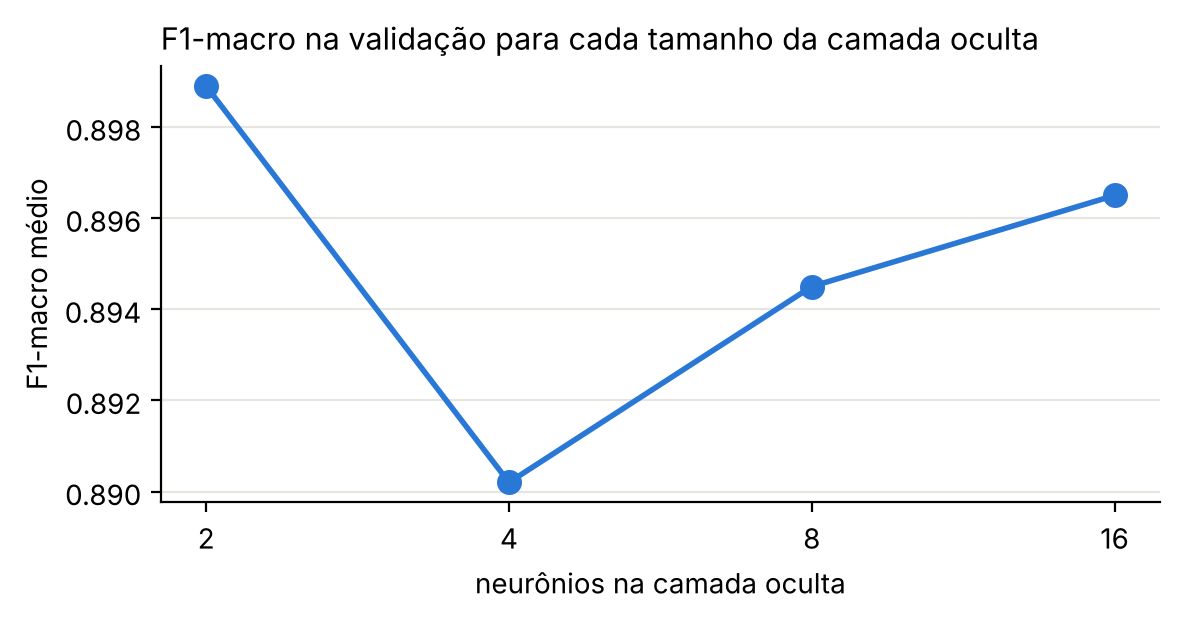

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(busca['neuronios'].astype(str), busca['f1_macro'], color='#2a78d6', linewidth=2, marker='o', markersize=8)
melhor = busca.loc[busca['f1_macro'].idxmax()]
ax.annotate(f"{melhor['f1_macro']:.3f}", (str(melhor['neuronios']), melhor['f1_macro']),
            textcoords='offset points', xytext=(0, 8), ha='center', color='#0b0b0b')
ax.set_xlabel('neurônios na camada oculta'); ax.set_ylabel('F1-macro médio')
ax.set_title('F1-macro na validação para cada tamanho da camada oculta', loc='left', fontsize=11)
ax.grid(axis='y', color='#e6e5e0', linewidth=0.8); ax.set_axisbelow(True)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

### Decisão

As diferenças entre 2, 8 e 16 neurônios (poucos milésimos) são **muito menores que o desvio padrão entre as partes** (cerca de 0,03): na prática, é empate. Mantemos **8 neurônios**, a configuração da rede usada no voto do Modelo 8. Assim, este modelo é exatamente o componente que foi submetido no voto (0,89900 no Kaggle), e as três submissões individuais (Modelos 9, 10 e 11) reproduzem aquele voto.

In [8]:
H = 8
print('melhor na busca:', int(busca.loc[busca['f1_macro'].idxmax(), 'neuronios']), 'neurônios | usado:', H)
print(busca.set_index('neuronios').loc[[int(busca.loc[busca['f1_macro'].idxmax(), 'neuronios']), H], ['f1_macro', 'dp_f1']])
criar_final = lambda: criar_rede(H)

melhor na busca: 2 neurônios | usado: 8
           f1_macro   dp_f1
neuronios                  
2            0.8989  0.0302
8            0.8945  0.0303


### Sensibilidade à inicialização aleatória

A rede começa com pesos sorteados. Para mostrar que o resultado não depende de um sorteio de sorte, repetimos a avaliação com outras 4 inicializações (mesmas partes da semente 777, 5 partes × 1 repetição para ser rápido).

In [9]:
linhas = []
for ini in [0, 1, 2, 3, 4]:
    def criar():
        m = criar_rede(H); m.base.set_params(mlpclassifier__random_state=ini); return m
    tab, _ = validar(criar, tr, y, semente=777, repeticoes=1)
    linhas.append({'inicialização': ini, 'f1_macro': round(tab['f1_macro'].mean(), 4)})
pd.DataFrame(linhas)

,inicialização,f1_macro
0,0,0.8902
1,1,0.8903
2,2,0.8883
3,3,0.8884
4,4,0.8942


## 6. Avaliação final — validação cruzada com outra semente (Aula 7)

5 partes × 4 repetições, semente 777. Métricas da aula 7: acurácia, precisão, recall (cobertura) de cada classe e F1. O F1-macro é a média do F1 das duas classes.

In [10]:
tab, prev = validar(criar_final, tr, y, semente=777)
resumo(tab)

,média,desvio padrão
f1_macro,0.886,0.031
acuracia,0.887,0.031
precisao_macro,0.888,0.030
recall_diabetes,0.870,0.047
recall_controle,0.904,0.047


### Matriz de confusão (média por repetição; cada repetição prevê os 520 pacientes uma vez)

In [11]:
matriz_confusao(y, prev)

,previsto controle (0),previsto diabetes (1)
real controle (0),226.0,24.0
real diabetes (1),35.0,235.0


### Onde estão os erros

In [12]:
erros_por_padrao(tr, y, prev)

pacientes  erros_medios  taxa_erro
padrão          classe                                      
glicose e HbA1c controle        173         13.75       0.08
                diabetes        184         21.75       0.12
nenhum exame    controle         11          2.00       0.18
                diabetes          7          3.00       0.43
só HbA1c        controle         19          0.75       0.04
                diabetes         22          1.75       0.08
só glicose      controle         47          7.50       0.16
                diabetes         57          8.50       0.15

## 7. Treino com todos os dados e previsão do teste

O modelo final é treinado com os 520 pacientes do treino e prevê os 312 do teste. O arquivo segue o formato `id,class` do `submission_template.csv`.

In [13]:
modelo = criar_final().fit(tr, y)
prev_teste = modelo.predict(te)
sub = pd.DataFrame({'id': te['id'], 'class': prev_teste})
sub.to_csv('submissao_rede_padroes.csv', index=False)
print('submissao_rede_padroes.csv:', len(sub), 'linhas | diabetes previsto em', f'{prev_teste.mean():.1%}', 'do teste')
print('por padrão de exames:')
print(pd.Series(prev_teste).groupby([NOME_PADRAO[p] for p in padrao_de(te)]).agg(['size', 'mean']).round(2))

submissao_rede_padroes.csv: 312 linhas | diabetes previsto em 49.4% do teste
por padrão de exames:
                 size  mean
glicose e HbA1c   222  0.48
nenhum exame       11  0.64
só HbA1c           26  0.50
só glicose         53  0.51


### Conferência do arquivo

In [14]:
chk = pd.read_csv('submissao_rede_padroes.csv')
tpl = pd.read_csv('../dados/kaggle-test/test.csv', usecols=['id'])
assert list(chk.columns) == ['id', 'class']
assert chk['id'].tolist() == tpl['id'].tolist()
assert set(chk['class']) <= {0, 1}
print('OK: mesmas', len(chk), 'linhas e ordem de ids do teste; classes 0/1')

OK: mesmas 312 linhas e ordem de ids do teste; classes 0/1
